In [1]:
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import numpy as np
import xarray as xr
from matplotlib import pyplot as plt
from matplotlib import rcParams, colors
from matplotlib import ticker as mticker
import geopandas as gpd
rcParams.update({'figure.autolayout': False})
import os
import wrf
from cartopy import crs as ccrs
from cartopy.feature import ShapelyFeature
from cartopy.io.shapereader import Reader
from cartopy.mpl.gridliner import LATITUDE_FORMATTER, LONGITUDE_FORMATTER
from shapely.geometry import mapping
import glob
import pandas as pd
import pickle
import rioxarray
import xesmf as xe
import dask
from dask.distributed import Client, LocalCluster
from dask import delayed
import dask.array as da
from dask_jobqueue import PBSCluster
import xarray as xr
from concurrent.futures import ProcessPoolExecutor
import calendar
import zarr
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

In [5]:
ds_t2 = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/AMJJAS_anom/VAR_2T_ERA5_India_AMJJAS_anom.nc', chunks='auto')

In [6]:
ds_da = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/L1/dyn_adj/MSL_1950/dyn_adj_ERA5_India_50_34_20_74.nc', chunks='auto')

In [7]:
ds_t2_masked = ds_t2.sel(time=ds_da.time, lat=ds_da.lat, lon=ds_da.lon)

In [8]:
ds_diff = dask.delayed(ds_t2_masked['anom'] - ds_da['dynamic'])

In [9]:
ds_diff = ds_diff.compute()

[Text(0, 0, '1-May'),
 Text(9, 0, '10-May'),
 Text(19, 0, '20-May'),
 Text(31, 0, '1-June'),
 Text(40, 0, '10-June'),
 Text(50, 0, '20-June'),
 Text(60, 0, '30-June')]

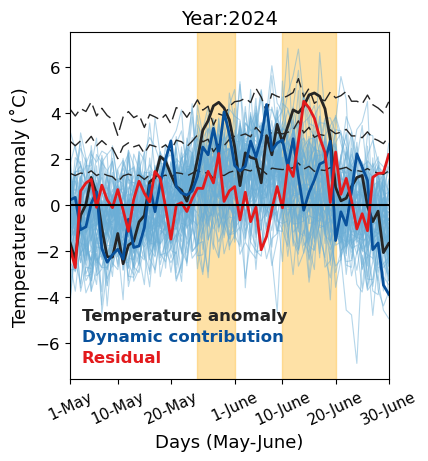

In [10]:
f = plt.figure(figsize=(4.25,4.75))
gs1 = gridspec.GridSpec(1,1)

gs1.update(left=0.18, right=0.93, bottom=0.18, top=0.91, wspace=0.05, hspace=0.2)

ax1 = f.add_subplot(gs1[0,0])
lat_slice = slice(30,22)
lon_slice = slice(75,85)

dyn_color = '#08519c'
therm_color = '#e31a1c'
k_color = '#252525'

ds_dayrs = []
for yr in np.arange(1950,2024):
    tms = slice('%s-05-01' %(yr),'%s-06-30' %(yr))
    data = ds_da['dynamic'].sel(time=tms).sel(lon=lon_slice,lat=lat_slice).mean(dim=['lat','lon'])
    ds_dayrs.append(xr.DataArray(data.data))
    ax1.plot(data.data, color='#6baed6', alpha=0.5, lw=0.8)


datastd = xr.concat(ds_dayrs,dim='years').std(dim='years').compute().data

ax1.plot(datastd, color=k_color,lw=1, linestyle='--', dashes=(10, 4))
ax1.plot(datastd*2, color=k_color,lw=1, linestyle='--', dashes=(10, 4))
ax1.plot(datastd*3, color=k_color,lw=1, linestyle='--', dashes=(10, 4))

yr=2024
tms = slice('%s-05-01' %(yr),'%s-06-30' %(yr))
data = ds_t2['anom'].sel(time=tms).sel(lon=lon_slice,lat=lat_slice).mean(dim=['lat','lon'])
ax1.plot(data.data, color=k_color,lw=2)

data = ds_da['dynamic'].sel(time=tms).sel(lon=lon_slice,lat=lat_slice).mean(dim=['lat','lon'])
ax1.plot(data.data, color=dyn_color,lw=2)

data = ds_diff.sel(time=tms).sel(lon=lon_slice,lat=lat_slice).mean(dim=['lat','lon'])
ax1.plot(data.data, color=therm_color,lw=2)

ax1.text(2.25,-5,'Temperature anomaly',fontsize=12, color=k_color,fontweight='bold')
ax1.text(2.25,-5.9,'Dynamic contribution',fontsize=12, color=dyn_color,fontweight='bold')
ax1.text(2.25,-6.8,'Residual',fontsize=12, color=therm_color,fontweight='bold')


ax1.set_ylabel('Temperature anomaly (˚C)', fontsize=13)
ax1.set_xlabel('Days (May-June)', fontsize=13)
ax1.tick_params(axis='both', labelsize=12)
ax1.set_title('Year:2024', fontsize=14)
plt.axhline(y=0, color='k')
plt.axvspan(24, 31, color='#fec44f', alpha=0.5, label='Span 1 (25–30)')
plt.axvspan(40, 50, color='#fec44f', alpha=0.5, label='Span 2 (43–49)')
ax1.set_xlim([0,60])
ax1.set_xticks([0, 9, 19, 31, 40, 50, 60])
ax1.set_xticklabels(['1-May', '10-May', '20-May', '1-June', '10-June', '20-June', '30-June'], fontsize=11, rotation=25)
#plt.savefig("Fig2-ts_heatwave-event.pdf",dpi=300,format='pdf',transparent=True)